# Own Challenge: individual contributions

**companydocs-rag**: a local RAG pipeline that answers questions about public Dutch
business documents (cao's, legislation, model agreements, privacy guidance) for
staffing, secondment and technical companies, with the cited source shown for every
answer.

| | |
|---|---|
| Repository | [github.com/companydocs-rag/companydocs-rag](https://github.com/companydocs-rag/companydocs-rag) |
| Approval | **The challenge was approved by the lecturer, Alican Noyan** (GitHub `@AlicanNoyan`). |
| Team | Roef Peters (`@RoefPeters254337`), Rutger Baas (`@RutgerBaas252706`), Lucan den Dekker (`@LucandenDekker251285`) |
| Per person | Roef: chunking strategy. Rutger: retrieval strategy (reranker) and the question set. Lucan: interface with highlighted sources. |

This notebook is the evidence for the individual contributions: per person **what they
worked on, what they changed or tested, and what effect it had**, with links to the
code and configuration and with tables and figures **computed from the result files
committed in the repository** (`evaluation/results/`, `experiments/lucan/`), so every
number can be traced to a measurement. The short written summary is
[`docs/CONTRIBUTIONS.md`](https://github.com/companydocs-rag/companydocs-rag/blob/main/docs/CONTRIBUTIONS.md);
each experiment has its own write-up in `experiments/<name>/README.md`.

## How the work was divided

The pipeline itself (text extraction with OCR, chunking, hybrid retrieval, answers from
a local language model, a browser demo) started from the team's earlier client
project and was renamed and adapted to this public corpus. That foundation was split
over the three of us so that each committed a part of it; on top of it each person ran
one experiment, in their own branch and pull request. Every commit is under the name
of the person who made it.

| step | who | what | merged |
|---|---|---|---|
| foundation | Lucan | project setup, configuration, documentation, the 26-document corpus, the evaluation script | 2026-11-04 |
| foundation, PR #1 | Roef | parse pass with OCR, normalization, structure-aware chunker (3 commits) | 2026-11-04 |
| foundation, PR #2 | Rutger | embeddings, Qdrant index, hybrid search, metadata prototype (3 commits) | 2026-11-05 |
| foundation, PR #3 / #4 | Lucan | answer layer, demo interface, documentation (3 commits) | 2026-11-05 |
| experiment | Rutger | judge reranker and the 100-question set (6 commits) | 2026-11-06 |
| experiment, PR #5 | Roef | chunking strategy (2 commits) | 2026-11-20 |
| experiment, PR #6 | Lucan | highlighted sources (3 commits) | 2026-11-20 |

In [1]:
import json
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "evaluation" / "results"
METRICS = ["page_hit@1", "page_hit@3", "page_hit@10", "mrr"]


def load(label):
    return json.loads((RESULTS / f"{label}.json").read_text(encoding="utf-8"))


def table(runs):
    head = "| run | questions | " + " | ".join(METRICS) + " |"
    rows = [head, "|" + "---|" * (len(METRICS) + 2)]
    for name, run in runs.items():
        s = run["summary"]
        rows.append(
            f"| {name} | {run['questions']} | "
            + " | ".join(f"{s[m]:.3f}" for m in METRICS)
            + " |"
        )
    display(Markdown("\n".join(rows)))


def chart(runs, title):
    fig, ax = plt.subplots(figsize=(8, 3.2))
    width = 0.8 / len(runs)
    for i, (name, run) in enumerate(runs.items()):
        xs = [x + i * width for x in range(len(METRICS))]
        ax.bar(xs, [run["summary"][m] for m in METRICS], width, label=name)
    ax.set_xticks([x + width * (len(runs) - 1) / 2 for x in range(len(METRICS))])
    ax.set_xticklabels(METRICS)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.show()


def reciprocal_ranks(run):
    return {
        q["question_id"]: (1 / q["page_rank"] if q["page_rank"] else 0.0)
        for q in run["per_question"]
    }


def sign_test(base, other):
    a, b = reciprocal_ranks(base), reciprocal_ranks(other)
    better = sum(1 for q in a if b[q] > a[q])
    worse = sum(1 for q in a if b[q] < a[q])
    n, k = better + worse, min(better, worse)
    p = min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2**n) if n else 1.0
    return better, worse, p

## Shared baseline

All three experiments are measured on the same question set: 100 questions with the
expected source and page (`evaluation/questions.csv`), scored with
`scripts/evaluate_retrieval.py`. `page_hit@k` is the share of questions with the
right page in the top k results; MRR is the mean reciprocal rank of the first right
page. Roef and Rutger each measured the baseline on their own machine; the two runs
are identical, so the measurement is reproducible.

In [2]:
baseline = load("rutger-baseline")
table({"baseline (Rutger's machine)": baseline, "baseline (Roef's machine)": load("roef-baseline")})

| run | questions | page_hit@1 | page_hit@3 | page_hit@10 | mrr |
|---|---|---|---|---|---|
| baseline (Rutger's machine) | 100 | 0.370 | 0.520 | 0.770 | 0.486 |
| baseline (Roef's machine) | 100 | 0.370 | 0.520 | 0.770 | 0.486 |

## Roef: chunking strategy

**What he worked on.** How the documents are cut into chunks: the baseline cuts on
article and clause numbering (structure-aware); the alternative cuts into pieces of a
fixed length.

**What he changed or tested.** A new setting `chunking.strategy` (default
`structure_aware`, alternative `fixed_length`) in `src/companydocs_rag/chunking/`,
with tests; fixed lengths of 600, 1,200 and 2,000 characters
(`experiments/roef/settings*.yaml`), each with its own index, against the baseline.
Pull request #5; change note `specs/002-chunking-strategy.md`.

**What effect it had:**

| run | questions | page_hit@1 | page_hit@3 | page_hit@10 | mrr |
|---|---|---|---|---|---|
| baseline (structure-aware) | 100 | 0.370 | 0.520 | 0.770 | 0.486 |
| fixed 600 | 100 | 0.270 | 0.550 | 0.790 | 0.435 |
| fixed 1,200 | 100 | 0.320 | 0.500 | 0.720 | 0.443 |
| fixed 2,000 | 100 | 0.280 | 0.550 | 0.750 | 0.446 |

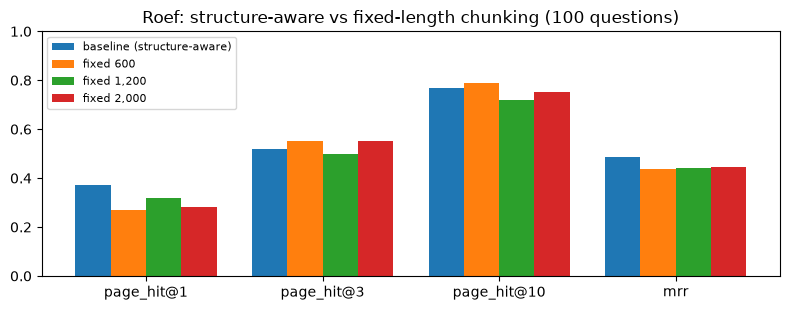

Fixed 1,200 against the baseline, per question: **37 worse, 16 better** (two-sided sign test p = 0.0055).

In [3]:
roef = {
    "baseline (structure-aware)": load("roef-baseline"),
    "fixed 600": load("roef-fixed-600"),
    "fixed 1,200": load("roef-fixed-1200"),
    "fixed 2,000": load("roef-fixed-2000"),
}
table(roef)
chart(roef, "Roef: structure-aware vs fixed-length chunking (100 questions)")
better, worse, p = sign_test(roef["baseline (structure-aware)"], roef["fixed 1,200"])
display(Markdown(
    f"Fixed 1,200 against the baseline, per question: **{worse} worse, {better} better** "
    f"(two-sided sign test p = {p:.4f})."
))

Fixed-length chunking is worse at every size, mainly at rank 1; chunk size itself
barely matters. Structure-aware chunking stays the default.

**Code and evidence:**
[pull request #5](https://github.com/companydocs-rag/companydocs-rag/pull/5) ·
[`chunking/chunker.py`](https://github.com/companydocs-rag/companydocs-rag/blob/main/src/companydocs_rag/chunking/chunker.py) ·
[`experiments/roef/`](https://github.com/companydocs-rag/companydocs-rag/tree/main/experiments/roef)
(settings, comparison script, write-up) ·
[`specs/002-chunking-strategy.md`](https://github.com/companydocs-rag/companydocs-rag/blob/main/specs/002-chunking-strategy.md) ·
results `evaluation/results/roef-*.json`

## Rutger: retrieval strategy (reranker)

**What he worked on.** How the retrieved passages are ranked: the baseline ranks by
hybrid search (dense embeddings plus BM25, fused with reciprocal rank fusion); the
alternative lets a small judge model rerank the top 20.

**What he changed or tested.** A setting `retrieval.reranker` (default `none`,
alternative `judge`) with `src/companydocs_rag/retrieval/judge.py`, changes in
`search.py` and `vectorstore/store.py`, and tests. The judge is Qwen3.5-0.8B,
fine-tuned on ConditionalQA (not on our questions) and, in the main setup, also
weight-edited (`experiments/rutger/`). He also wrote the 100 questions. Change note
`specs/001-judge-route.md`.

**What effect it had:**

| run | questions | page_hit@1 | page_hit@3 | page_hit@10 | mrr |
|---|---|---|---|---|---|
| baseline (hybrid) | 100 | 0.370 | 0.520 | 0.770 | 0.486 |
| judge, fine-tuned | 100 | 0.690 | 0.840 | 0.930 | 0.778 |
| judge, fine-tuned and edited | 100 | 0.630 | 0.830 | 0.960 | 0.740 |

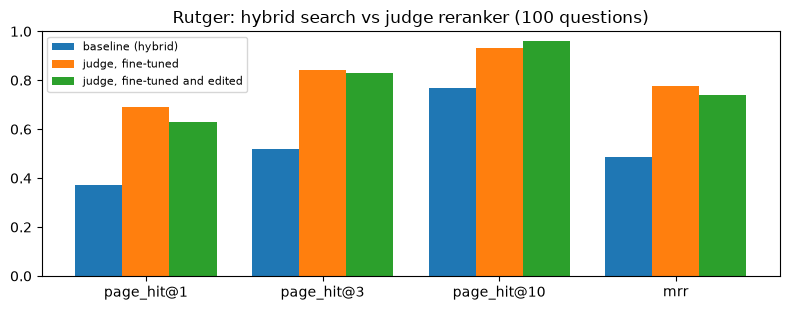

Edited judge against the baseline, per question: **49 better, 14 worse** (two-sided sign test p = 1.1e-05).

In [4]:
rutger = {
    "baseline (hybrid)": baseline,
    "judge, fine-tuned": load("rutger-judge-tuned"),
    "judge, fine-tuned and edited": load("rutger-judge-edited"),
}
table(rutger)
chart(rutger, "Rutger: hybrid search vs judge reranker (100 questions)")
better, worse, p = sign_test(baseline, rutger["judge, fine-tuned and edited"])
display(Markdown(
    f"Edited judge against the baseline, per question: **{better} better, {worse} worse** "
    f"(two-sided sign test p = {p:.2g})."
))

The reranker puts the right page first far more often. It costs about 18 seconds per
question on a GPU, so it stays behind the setting and the baseline remains the
default.

**Code and evidence:**
[`retrieval/judge.py`](https://github.com/companydocs-rag/companydocs-rag/blob/main/src/companydocs_rag/retrieval/judge.py) ·
[`experiments/rutger/`](https://github.com/companydocs-rag/companydocs-rag/tree/main/experiments/rutger)
(settings, training and editing lab, write-up) ·
[`specs/001-judge-route.md`](https://github.com/companydocs-rag/companydocs-rag/blob/main/specs/001-judge-route.md) ·
[`evaluation/questions.csv`](https://github.com/companydocs-rag/companydocs-rag/blob/main/evaluation/questions.csv) ·
results `evaluation/results/rutger-*.json`

## Lucan: interface with highlighted sources

**What he worked on.** How a user checks an answer against its source: the baseline
interface shows the cited page as an image; the user has to find the passage
themselves.

**What he changed or tested.** A workspace interface (chat, document library, page
viewer) in `src/companydocs_rag/interface/`, with tests, that highlights the cited
passage on the PDF page (`highlight.py`): the chunk's text is aligned with the page's
words, and a highlight is only drawn when the match is strong enough. Measured with
`experiments/lucan/measure_highlight.py` on the 90 answerable questions. Pull request
#6.

**What effect it had:**

| measure | baseline | workspace |
|---|---|---|
| answer passages with a highlight (466) | 0% | 99.8% |
| questions with a highlighted answer passage (90) | 0% | 100% |
| passage words found (median) | - | 100% |
| share of the page the user is pointed to (median) | 100% | 7.7% |
| retrieved top-5 pages with a highlight (450) | 0% | 100% |

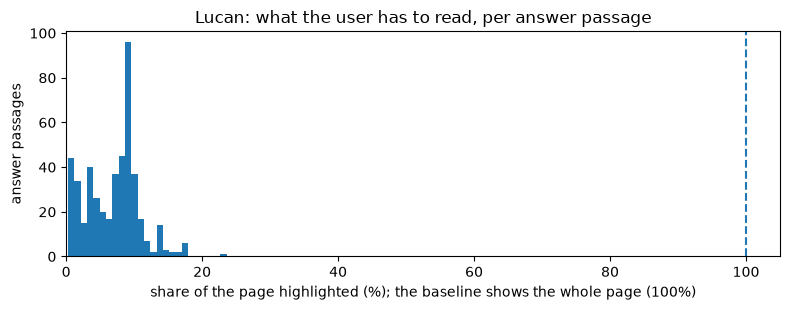

In [5]:
lucan = json.loads(
    (ROOT / "experiments" / "lucan" / "highlight_results.json").read_text(encoding="utf-8")
)
answer = lucan["answer_passages"]
retrieved = lucan["retrieved_passages"]
pairs = answer["pairs"]
drawn = [p for p in pairs if p["drawn"]]
rows = [
    "| measure | baseline | workspace |",
    "|---|---|---|",
    f"| answer passages with a highlight ({len(pairs)}) | 0% | "
    f"{len(drawn) / len(pairs):.1%} |",
    f"| questions with a highlighted answer passage ({lucan['questions_answerable']}) | 0% | "
    f"{answer['questions_with_highlight']:.0%} |",
    f"| passage words found (median) | - | {answer['all']['median_coverage_drawn']:.0%} |",
    f"| share of the page the user is pointed to (median) | 100% | "
    f"{answer['all']['median_area_drawn']:.1%} |",
    f"| retrieved top-5 pages with a highlight ({retrieved['candidate_pages']['pairs']}) "
    f"| 0% | {retrieved['candidate_pages']['drawn']:.0%} |",
]
display(Markdown("\n".join(rows)))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist([p["area"] * 100 for p in drawn], bins=25)
ax.axvline(100, linestyle="--")
ax.set_xlim(0, 105)
ax.set_xlabel("share of the page highlighted (%); the baseline shows the whole page (100%)")
ax.set_ylabel("answer passages")
ax.set_title("Lucan: what the user has to read, per answer passage")
plt.tight_layout()
plt.show()

The highlight appears on every answer page in the question set and narrows what the
user has to read to about 8% of the page. Limits: only text-layer pages were measured
(no scanned answer pages in the set), the boxes were not checked visually, and the
effect on how fast users check answers was not measured.

**Code and evidence:**
[pull request #6](https://github.com/companydocs-rag/companydocs-rag/pull/6) ·
[`interface/highlight.py`](https://github.com/companydocs-rag/companydocs-rag/blob/main/src/companydocs_rag/interface/highlight.py) ·
[`experiments/lucan/`](https://github.com/companydocs-rag/companydocs-rag/tree/main/experiments/lucan)
(measurement script, results, write-up)

## Summary

| person | worked on | changed or tested | effect |
|---|---|---|---|
| Roef | chunking strategy | `chunking.strategy: fixed_length` at 600 / 1,200 / 2,000 characters against structure-aware chunking | fixed length is worse at every size (MRR 0.486 to 0.435-0.446); structure-aware stays the default |
| Rutger | retrieval strategy (reranking) | `retrieval.reranker: judge`, a fine-tuned and edited Qwen3.5-0.8B judge on the hybrid top 20 | MRR 0.486 to 0.740, page_hit@1 0.37 to 0.63, at about 18 s per question on a GPU |
| Lucan | interface: verifying answers against sources | workspace interface that highlights the cited passage on the page | highlight on 99.8% of answer passages; the user reads about 8% of the page instead of all of it |

## Reproducing

Clone the repository and follow the quick start in
[`README.md`](https://github.com/companydocs-rag/companydocs-rag/blob/main/README.md)
(full walkthrough in `docs/ONBOARDING.md`): `uv sync --python 3.12`, Tesseract 5.5.3
and Ollama; the 26 PDFs are in `data/raw/`; build the pipeline with
`companydocs-parse-pass`, `-normalize`, `-chunk` and `-index`; measure with
`scripts/evaluate_retrieval.py --label <name>`. Each experiment's README gives its own
commands. This notebook only reads the committed result files, so it runs without the
pipeline (Python with matplotlib). The test suite passes: 2542 passed, 1 expected
failure.

## Limitations of the project as a whole

- The question set (100 questions) was written by one team member; the experiments
  were not tuned on it (the reranker was trained on an external dataset).
- The full index takes hours on a laptop without a GPU; the retrieval part of the
  interface measurement used a preview index of 22 of the 26 documents.
- Everything runs locally by design (the demo is meant for companies' own documents);
  the optional hosted-model setting in `experiments/lucan/` is for the demo only.